In [1]:
import pandas as pd 
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
files = os.listdir(r"D:\xampp\htdocs\project\kodingakademi\Python\bootcamp data analis\pertemuan\data\uber-traffic")
files

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-janjune-15.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [3]:
files.remove('uber-raw-data-janjune-15.csv')

In [4]:
files

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [5]:
path = r"D:\xampp\htdocs\project\kodingakademi\Python\bootcamp data analis\pertemuan\data\uber-traffic"

final = pd.DataFrame()

for file in files:
    df = pd.read_csv(path + "/" + file, encoding = 'utf-8')
    final = pd.concat([df, final])

In [6]:
final.shape

(4534327, 4)

In [7]:
final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date/Time  object 
 1   Lat        float64
 2   Lon        float64
 3   Base       object 
dtypes: float64(2), object(2)
memory usage: 173.0+ MB


In [8]:
df = final.copy()
df

,Date/Time,Lat,Lon,Base
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512
3,9/1/2014 0:06:00,40.7450,-73.9889,B02512
4,9/1/2014 0:11:00,40.8145,-73.9444,B02512
...,...,...,...,...
564511,4/30/2014 23:22:00,40.7640,-73.9744,B02764
564512,4/30/2014 23:26:00,40.7629,-73.9672,B02764
564513,4/30/2014 23:31:00,40.7443,-73.9889,B02764
564514,4/30/2014 23:32:00,40.6756,-73.9405,B02764


In [9]:
df["Date/Time"] = pd.to_datetime(df["Date/Time"], format="%m/%d/%Y %H:%M:%S")

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Dtype         
---  ------     -----         
 0   Date/Time  datetime64[ns]
 1   Lat        float64       
 2   Lon        float64       
 3   Base       object        
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 173.0+ MB


In [11]:
df["weekday"] = df["Date/Time"].dt.day_name()
df["day"] = df["Date/Time"].dt.day 
df["minute"] = df["Date/Time"].dt.minute 
df["month"] = df["Date/Time"].dt.month 
df["hour"] = df["Date/Time"].dt.hour

In [12]:
df

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour
0,2014-09-01 00:01:00,40.2201,-74.0021,B02512,Monday,1,1,9,0
1,2014-09-01 00:01:00,40.7500,-74.0027,B02512,Monday,1,1,9,0
2,2014-09-01 00:03:00,40.7559,-73.9864,B02512,Monday,1,3,9,0
3,2014-09-01 00:06:00,40.7450,-73.9889,B02512,Monday,1,6,9,0
4,2014-09-01 00:11:00,40.8145,-73.9444,B02512,Monday,1,11,9,0
...,...,...,...,...,...,...,...,...,...
564511,2014-04-30 23:22:00,40.7640,-73.9744,B02764,Wednesday,30,22,4,23
564512,2014-04-30 23:26:00,40.7629,-73.9672,B02764,Wednesday,30,26,4,23
564513,2014-04-30 23:31:00,40.7443,-73.9889,B02764,Wednesday,30,31,4,23
564514,2014-04-30 23:32:00,40.6756,-73.9405,B02764,Wednesday,30,32,4,23


In [13]:
df["Base"].unique()

array(['B02512', 'B02598', 'B02617', 'B02682', 'B02764'], dtype=object)

In [14]:
df["day"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [15]:
df["weekday"].unique()

array(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday',
       'Sunday'], dtype=object)

In [16]:
import plotly.express as px

In [17]:
px.bar(x = df["weekday"].value_counts().index,
       y = df["weekday"].value_counts().values)

(array([216928., 103517., 227152., 543565., 324851., 366329., 819491.,
        660869., 579117., 692508.]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ]),
 <BarContainer object of 10 artists>)

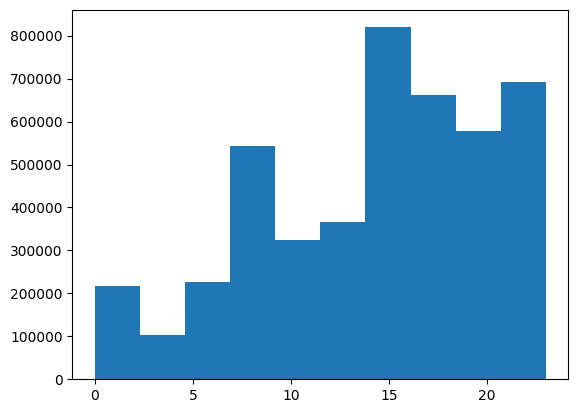

In [18]:
plt.hist(df["hour"])

In [29]:
df["month"].unique()

array([9, 5, 6, 7, 8, 4])

In [42]:
for i,month in enumerate(df["month"].unique()):
    print(month)

9
5
6
7
8
4


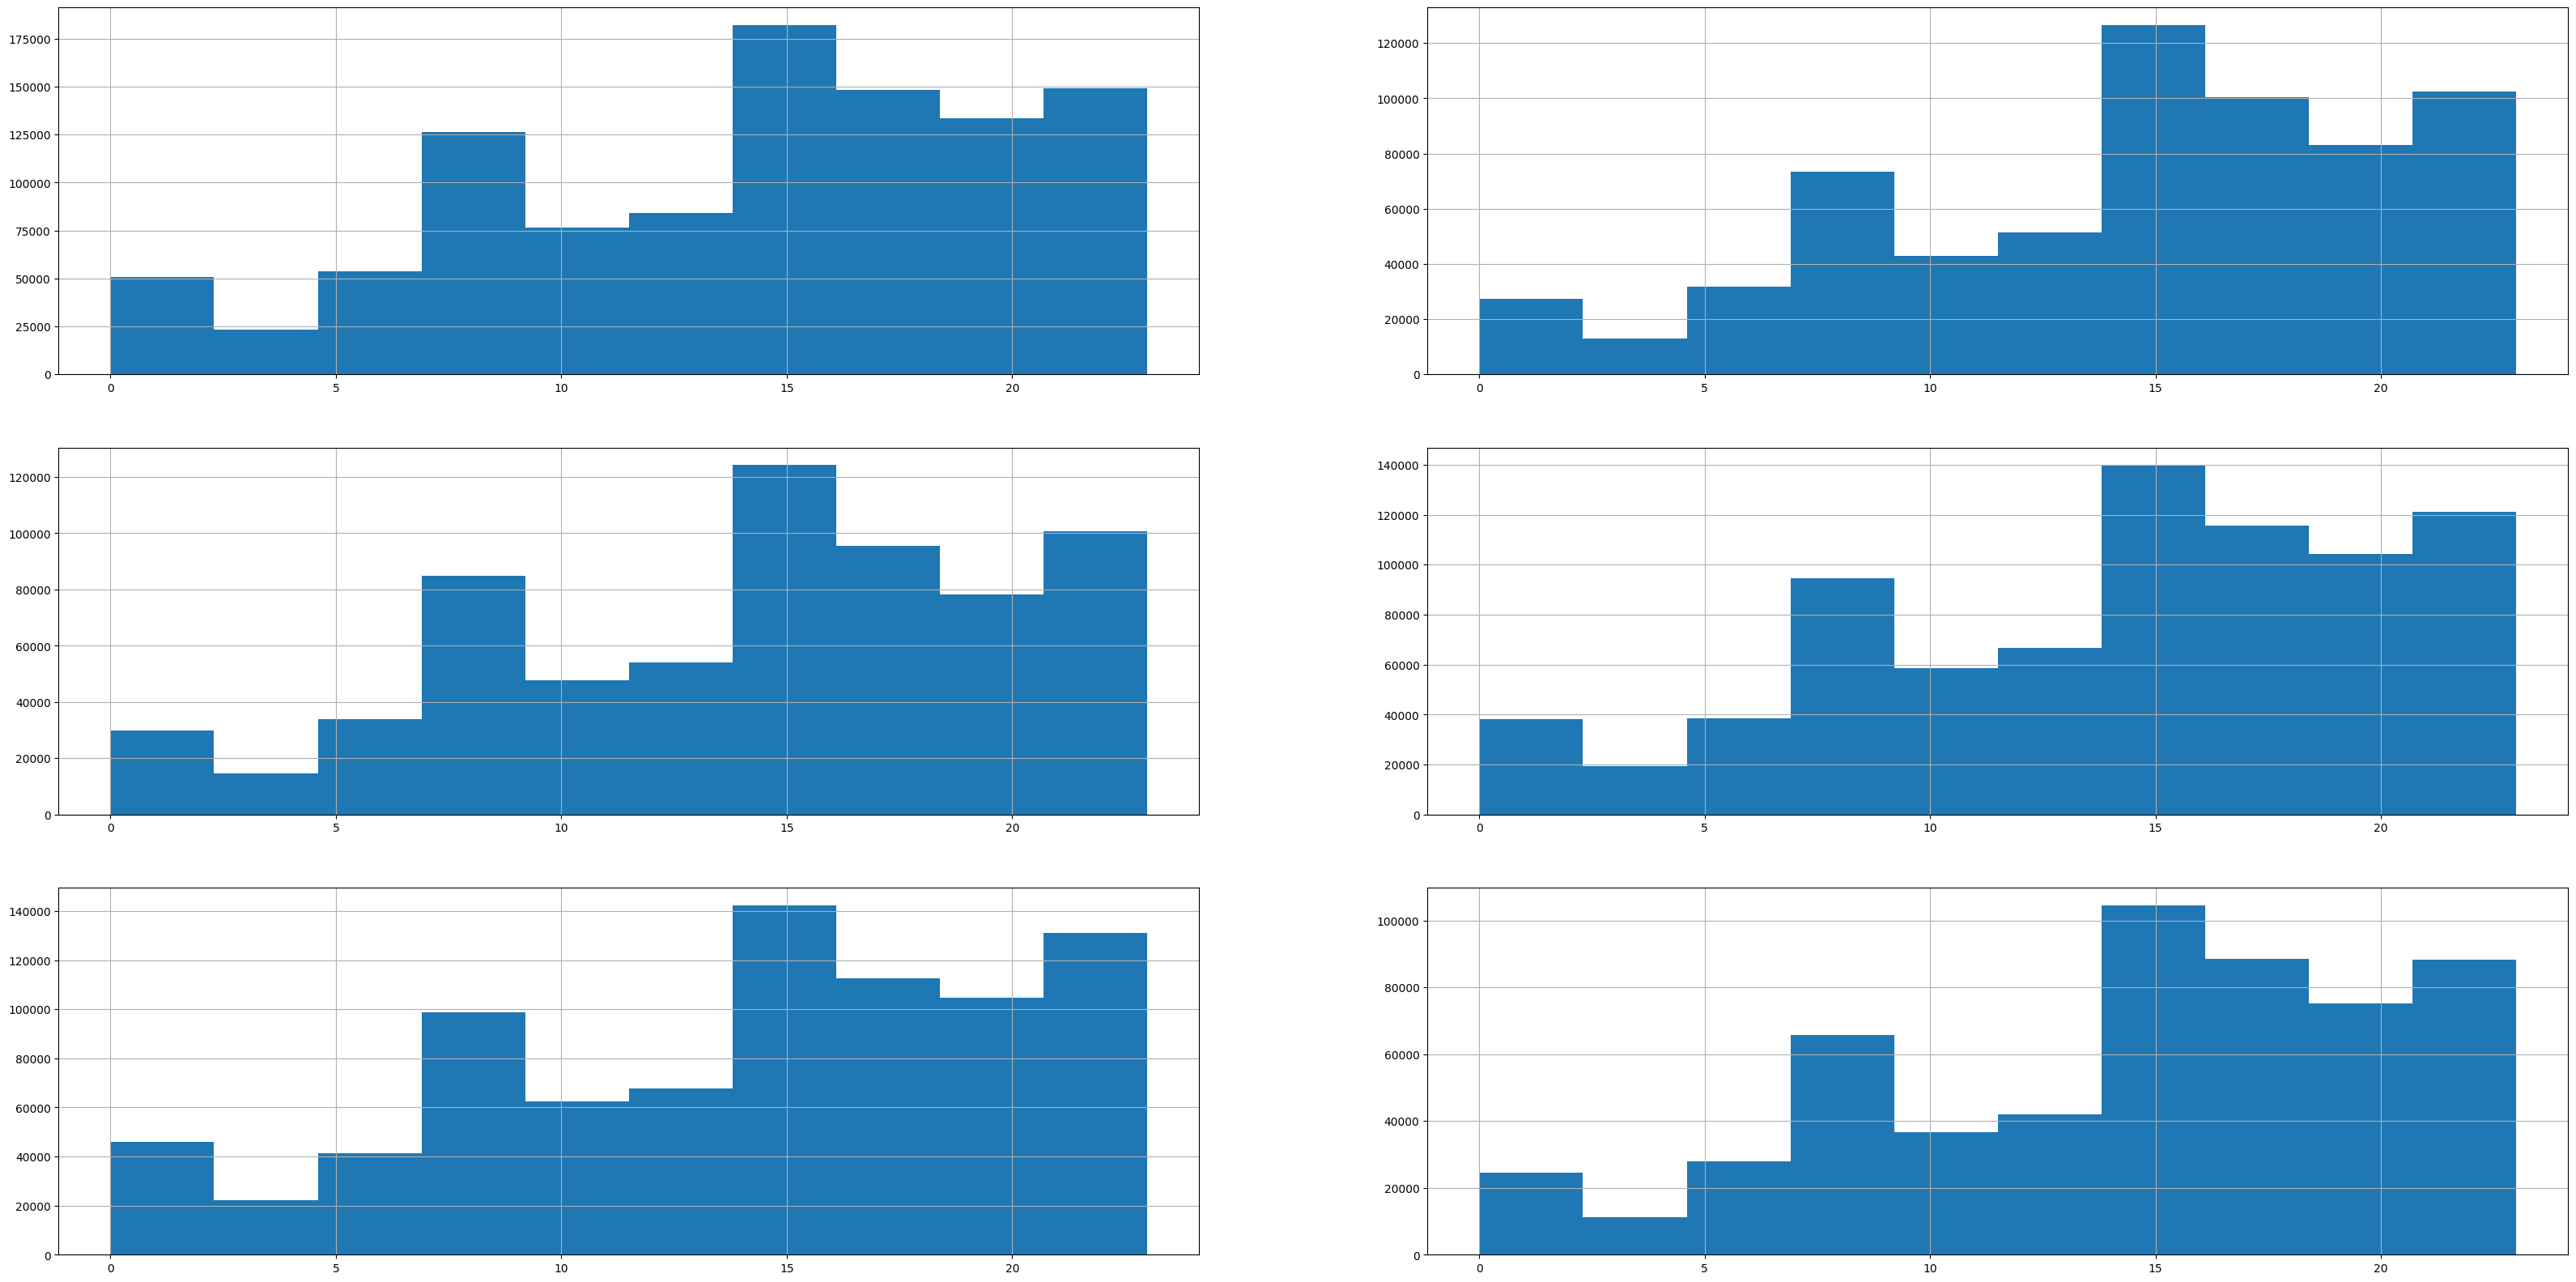

In [43]:
plt.figure(figsize=(40,20))
for i,month in enumerate(df["month"].unique()):
    plt.subplot(3,2,i+1)
    df[df["month"] == month]["hour"].hist()
    

In [44]:
for i in df["month"].unique():
    print(i)

9
5
6
7
8
4


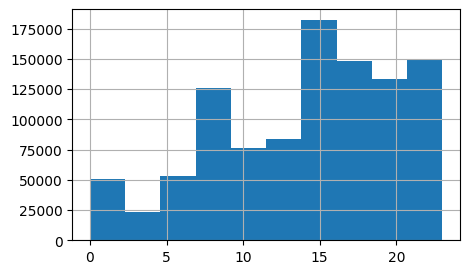

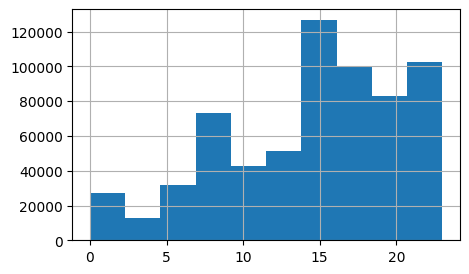

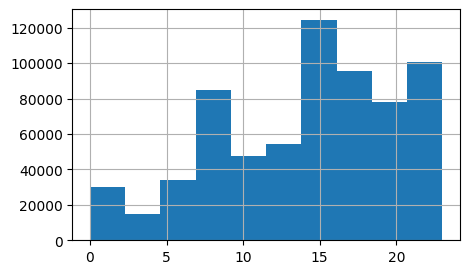

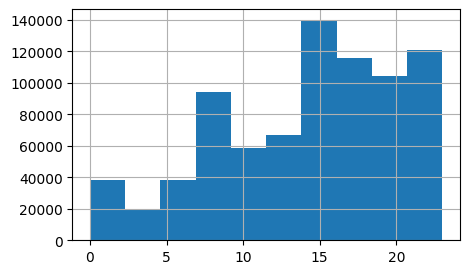

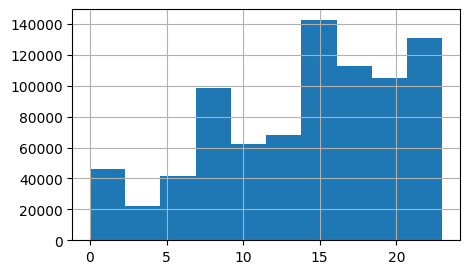

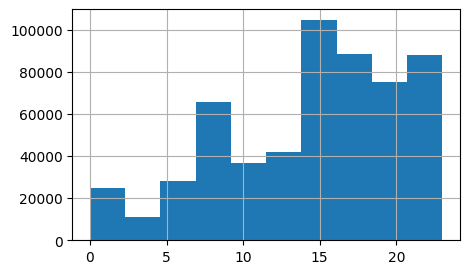

In [45]:
for i in df["month"].unique():
    plt.figure(figsize=(5,3))
    df[df["month"] == i]["hour"].hist()

In [46]:
df.head()

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour
0,2014-09-01 00:01:00,40.2201,-74.0021,B02512,Monday,1,1,9,0
1,2014-09-01 00:01:00,40.7500,-74.0027,B02512,Monday,1,1,9,0
2,2014-09-01 00:03:00,40.7559,-73.9864,B02512,Monday,1,3,9,0
3,2014-09-01 00:06:00,40.7450,-73.9889,B02512,Monday,1,6,9,0
4,2014-09-01 00:11:00,40.8145,-73.9444,B02512,Monday,1,11,9,0


In [48]:
group = df.groupby("month")["hour"].sum()
group

month
4     8165748
5     9448974
6     9386939
7    11321420
8    11658535
9    14488851
Name: hour, dtype: int32

In [51]:
plt.figure(figsize=(10,5))
px.bar(x = group.index,
       y = group.values)

<Figure size 1000x500 with 0 Axes>

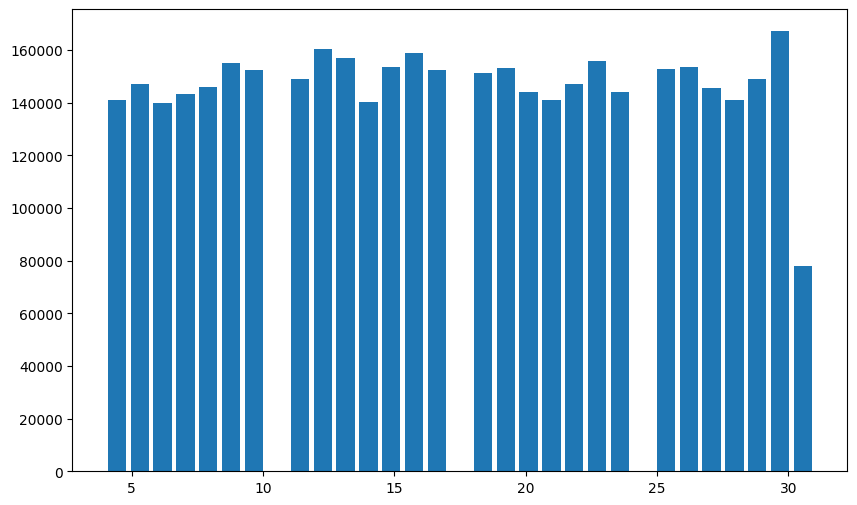

In [60]:
plt.figure(figsize=(10,6))
plt.hist(df["day"], bins=31, rwidth=0.8, range=(4, 31))
plt.show()

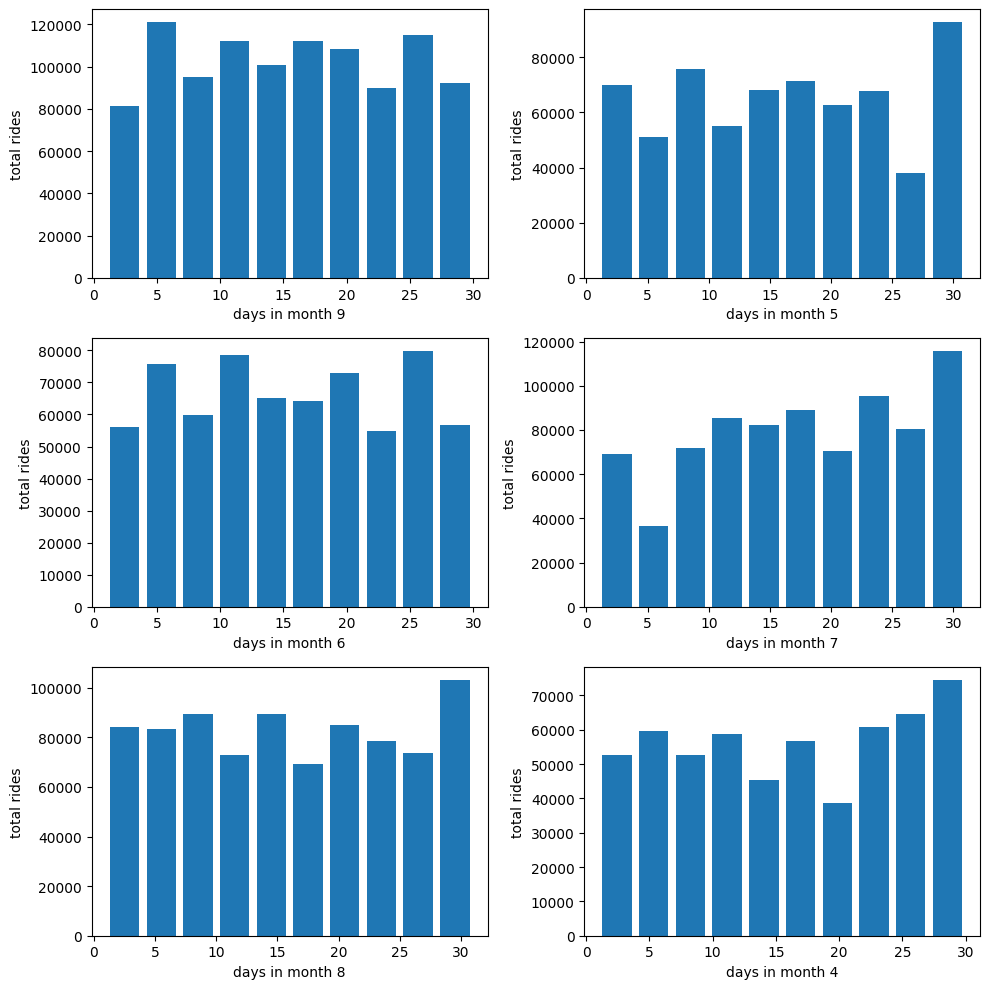

In [67]:
plt.figure(figsize=(10,10))
for i,month in enumerate(df["month"].unique(), 1):
    plt.subplot(3,2,i)
    df_out = df[df["month"] == month]
    plt.hist(df_out["day"], rwidth=0.8)
    plt.xlabel("days in month %d" %month)
    plt.ylabel("total rides")
    plt.tight_layout()

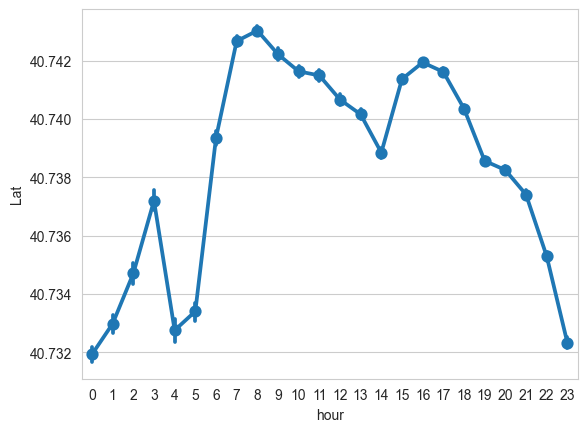

In [68]:
sns.set_style(style="whitegrid")
sns.pointplot(x = "hour", y = "Lat", data = df)
plt.show()

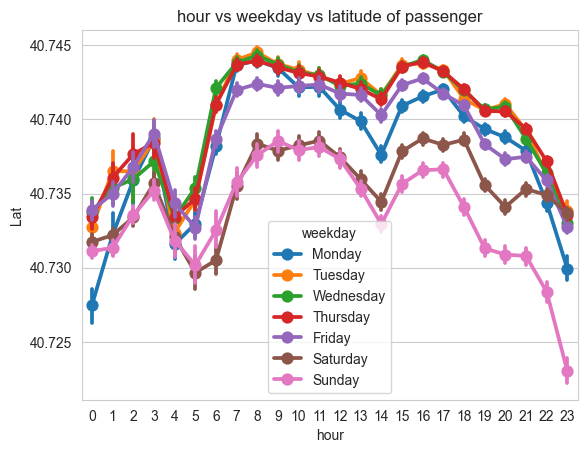

In [69]:
sns.pointplot(x="hour", y="Lat", hue="weekday", data = df)
plt.title("hour vs weekday vs latitude of passenger")
plt.show()

ASSIGNMENT

In [70]:
df.columns

Index(['Date/Time', 'Lat', 'Lon', 'Base', 'weekday', 'day', 'minute', 'month',
       'hour'],
      dtype='object')

In [82]:
# NO 1

base = df.groupby("Base")["Base"].count()
base

Base
B02512     205673
B02598    1393113
B02617    1458853
B02682    1212789
B02764     263899
Name: Base, dtype: int64

In [77]:
df["Base"].value_counts()

Base
B02617    1458853
B02598    1393113
B02682    1212789
B02764     263899
B02512     205673
Name: count, dtype: int64

In [74]:
base.idxmax()

'B02617'

In [84]:
px.line(x = base.index, y = base.values)

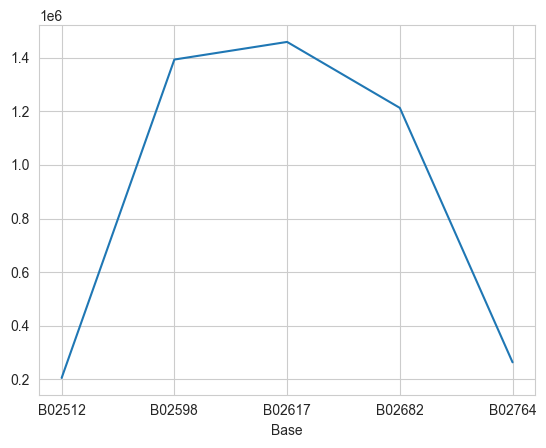

In [85]:
sns.lineplot(x = base.index, y = base.values)
plt.show()

<Axes: xlabel='Base', ylabel='count'>

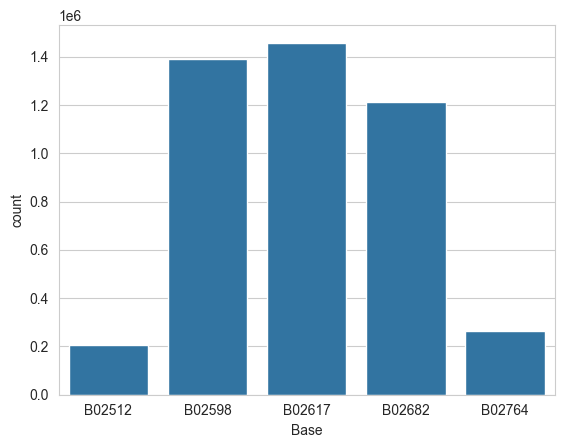

In [89]:
sns.countplot(x = "Base", data = df)

<Axes: xlabel='hour', ylabel='Lat'>

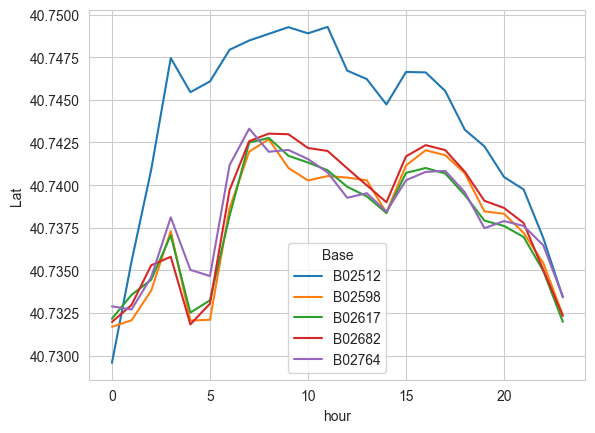

In [92]:
sns.lineplot(x="hour", y="Lat", hue="Base", data = df, errorbar=None)

UBER CROSS

In [100]:
by_cross = df.groupby(["weekday", "hour"]).apply(lambda x:len(x))
by_cross

C:\Users\agung\AppData\Local\Temp\ipykernel_144400\4140896678.py:1: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



weekday    hour
Friday     0       13716
           1        8163
           2        5350
           3        6930
           4        8806
                   ...  
Wednesday  19      47017
           20      47772
           21      44553
           22      32868
           23      18146
Length: 168, dtype: int64

In [95]:
pivot = by_cross.unstack()
pivot

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
Friday,13716,8163,5350,6930,8806,13450,23412,32061,31509,25230,...,36206,43673,48169,51961,54762,49595,43542,48323,49409,41260
Monday,6436,3737,2938,6232,9640,15032,23746,31159,29265,22197,...,28157,32744,38770,42023,37000,34159,32849,28925,20158,11811
Saturday,27633,19189,12710,9542,6846,7084,8579,11014,14411,17669,...,31418,38769,43512,42844,45883,41098,38714,43826,47951,43174
Sunday,32877,23015,15436,10597,6374,6169,6596,8728,12128,16401,...,28151,31112,33038,31521,28291,25948,25076,23967,19566,12166
Thursday,9293,5290,3719,5637,8505,14169,27065,37038,35431,27812,...,36699,44442,50560,56704,55825,51907,51990,51953,44194,27764
Tuesday,6237,3509,2571,4494,7548,14241,26872,36599,33934,25023,...,34846,41338,48667,55500,50186,44789,44661,39913,27712,14869
Wednesday,7644,4324,3141,4855,7511,13794,26943,36495,33826,25635,...,35148,43388,50684,55637,52732,47017,47772,44553,32868,18146


<Axes: xlabel='hour', ylabel='weekday'>

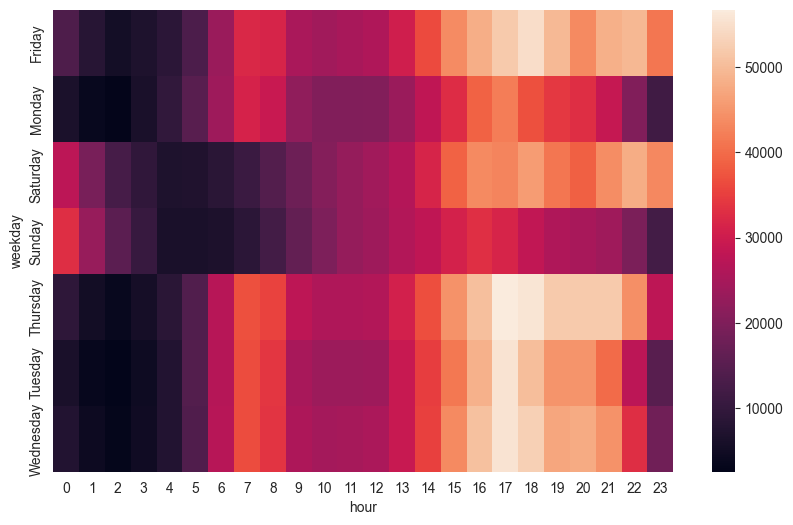

In [99]:
plt.figure(figsize=(10,6))
sns.heatmap(pivot)

C:\Users\agung\AppData\Local\Temp\ipykernel_144400\1352282941.py:2: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



<Axes: xlabel='month', ylabel='day'>

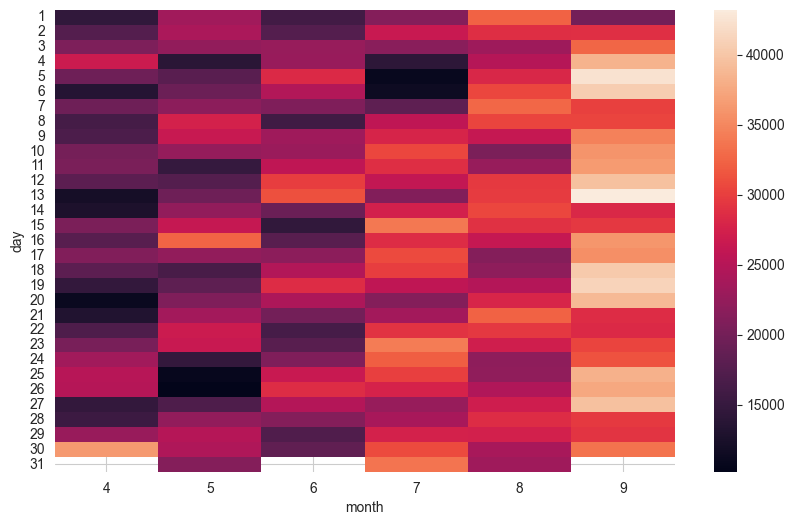

In [101]:
def heatmap(col1, col2):
    by_cross = df.groupby([col1, col2]).apply(lambda x:len(x))
    pivot = by_cross.unstack()
    plt.figure(figsize=(10,6))
    return sns.heatmap(pivot)

heatmap("day", "month")

C:\Users\agung\AppData\Local\Temp\ipykernel_144400\1352282941.py:2: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



<Axes: xlabel='hour', ylabel='day'>

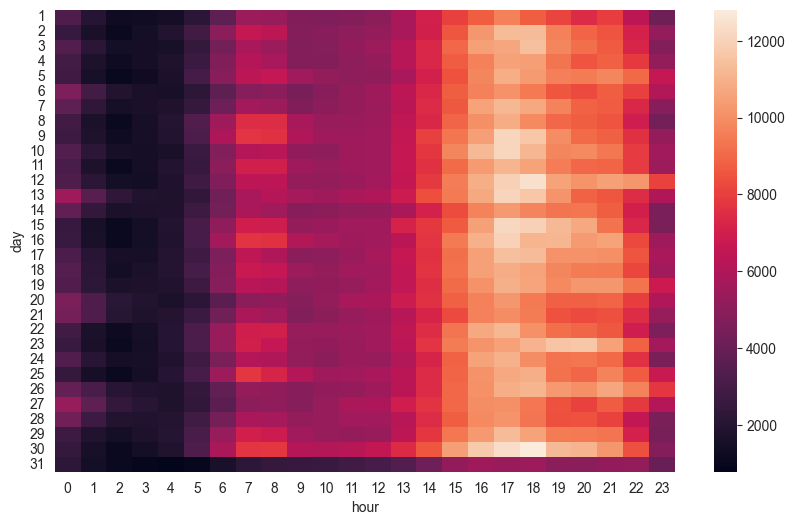

In [102]:
heatmap("day", "hour")

In [105]:
df = df[df["month"] == 4]

C:\Users\agung\AppData\Local\Temp\ipykernel_144400\1352282941.py:2: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



<Axes: xlabel='month', ylabel='weekday'>

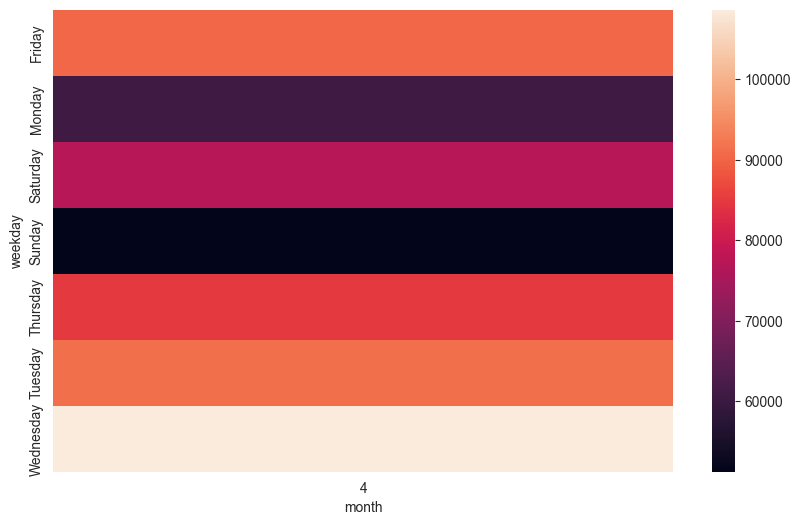

In [106]:
heatmap("weekday", "month")

(40.6, 41.0)

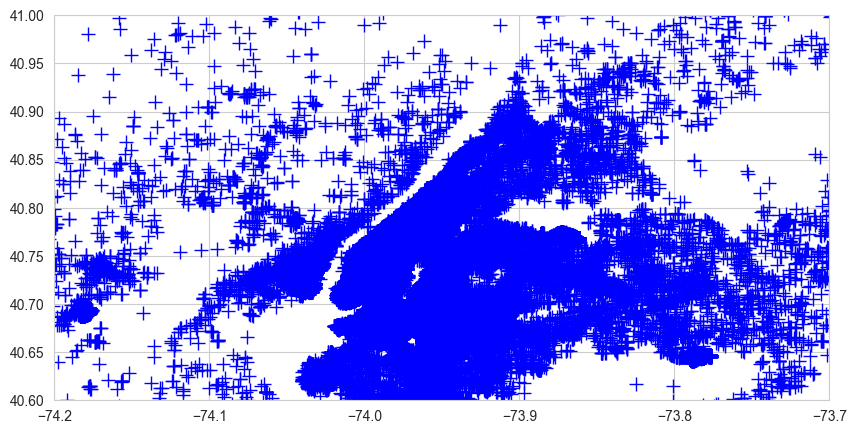

In [107]:
plt.figure(figsize=(10,5))

plt.plot(df["Lon"], df["Lat"], "b+", ms = 10)
plt.xlim(-74.2, -73.7)
plt.ylim(40.6, 41)

In [110]:
df_out = df[df["weekday"] == "Sunday"]
df_out.head()

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour
6965,2014-04-06 00:00:00,40.6547,-74.3033,B02512,Sunday,6,0,4,0
6966,2014-04-06 00:00:00,40.7356,-74.0006,B02512,Sunday,6,0,4,0
6967,2014-04-06 00:00:00,40.7421,-74.0041,B02512,Sunday,6,0,4,0
6968,2014-04-06 00:00:00,40.7401,-74.0053,B02512,Sunday,6,0,4,0
6969,2014-04-06 00:01:00,40.7368,-73.9877,B02512,Sunday,6,1,4,0


In [116]:
from folium.plugins import HeatMap
import folium 

basemap = folium.Map()

test = df_out.groupby(["Lat", "Lon"])["weekday"].count().reset_index()
HeatMap(test, zoom = 20, radius=15).add_to(basemap)

basemap

In [117]:
def plot_heatmap(df,day):
    df_out = df[df["weekday"] == day]
    test = df_out.groupby(["Lat", "Lon"])["weekday"].count().reset_index()
    HeatMap(test, zoom = 20, radius=15).add_to(basemap)
    return basemap

In [118]:
plot_heatmap(df, "monday")